Matplotlib is building the font cache; this may take a moment.


Number of images: 200
File: IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.tif
Shape: (520, 696)
Data type: uint16
Minimum pixel value: 120
Maximum pixel value: 4095
Mean pixel value: 248.14


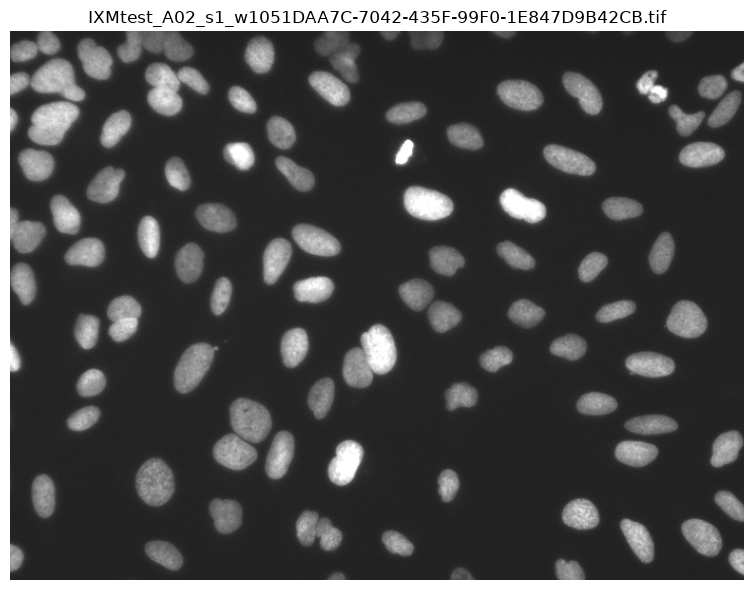

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from skimage import io


image_dir = Path("../data/raw/bbbc039/images")
image_paths = sorted(image_dir.glob("*.tif"))

print(f"Number of images: {len(image_paths)}")

image_path = image_paths[0]
image = io.imread(image_path)

print(f"File: {image_path.name}")
print(f"Shape: {image.shape}")
print(f"Data type: {image.dtype}")
print(f"Minimum pixel value: {image.min()}")
print(f"Maximum pixel value: {image.max()}")
print(f"Mean pixel value: {image.mean():.2f}")

display_max = np.percentile(image, 99.5)

plt.figure(figsize=(8, 6))
plt.imshow(image, cmap="gray", vmin=0, vmax=display_max)
plt.title(image_path.name)
plt.axis("off")
plt.tight_layout()
plt.show()

Number of images: 200
Image: IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.tif
Mask: IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.png
Mask exists: True
Image shape: (520, 696)
Mask shape: (520, 696, 4)
Number of annotated nuclei: 110


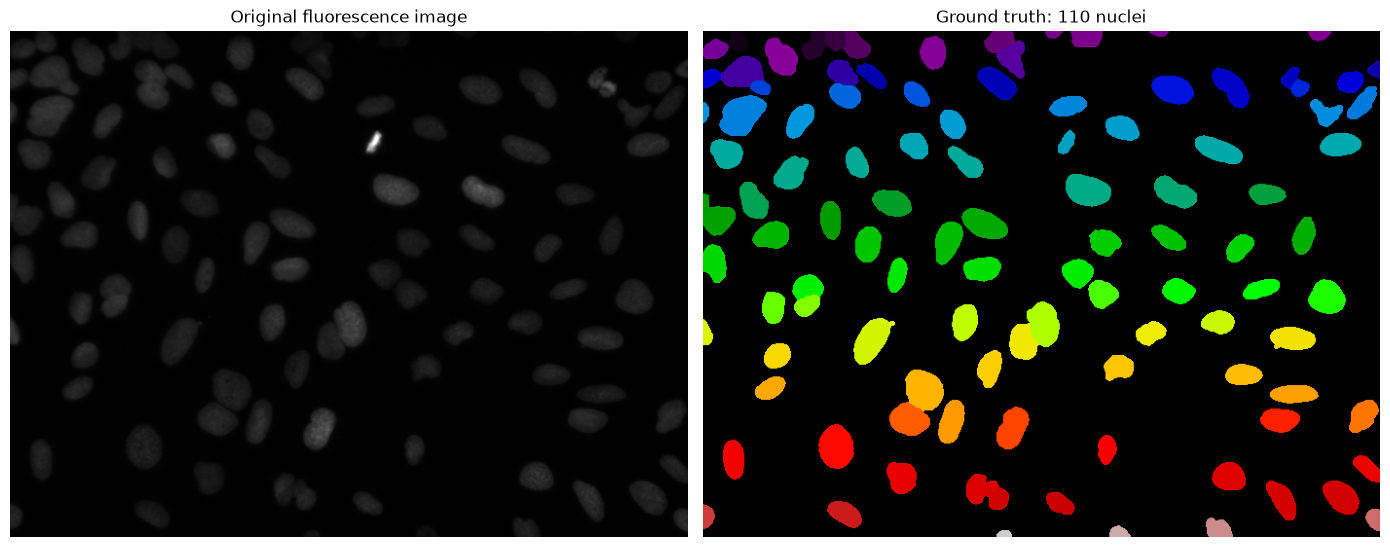

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from skimage import io, measure


image_dir = Path("../data/raw/bbbc039/images")
mask_dir = Path("../data/raw/bbbc039/masks")

image_paths = sorted(image_dir.glob("*.tif"))
print(f"Number of images: {len(image_paths)}")

if not image_paths:
    raise FileNotFoundError(f"No TIFF images found in {image_dir.resolve()}")

image_path = image_paths[0]
mask_path = mask_dir / f"{image_path.stem}.png"

print(f"Image: {image_path.name}")
print(f"Mask: {mask_path.name}")
print(f"Mask exists: {mask_path.exists()}")

if not mask_path.exists():
    raise FileNotFoundError(f"Mask not found: {mask_path.resolve()}")

image = io.imread(image_path)
mask_rgb = io.imread(mask_path)

if mask_rgb.ndim == 3:
    mask_raw = mask_rgb[:, :, 0]
else:
    mask_raw = mask_rgb

mask_labeled = measure.label(mask_raw)
number_of_nuclei = int(mask_labeled.max())

print(f"Image shape: {image.shape}")
print(f"Mask shape: {mask_rgb.shape}")
print(f"Number of annotated nuclei: {number_of_nuclei}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original fluorescence image")
axes[0].axis("off")

axes[1].imshow(mask_labeled, cmap="nipy_spectral")
axes[1].set_title(f"Ground truth: {number_of_nuclei} nuclei")
axes[1].axis("off")

plt.tight_layout()
plt.show()